Câu hỏi xuyên suốt: chỉ số cháy kiểu Nesterov (P) có đủ tin cậy để cảnh báo cháy rừng ở Việt Nam không? Câu trả lời ngắn: P có ích hơn khí hậu thuần túy nhưng yếu hơn một biến đo ngay trong ngày, không dùng chung được giữa các vùng, và bỏ qua những thứ quyết định cháy như đà của đợt cháy và hoạt động của con người. Các chương đi từ P thua ở đâu, đến vì sao, rồi đến phần còn thiếu. Mỗi giả thuyết được nêu trước khi chạy, và kết quả quan trọng đều được đối chiếu bằng cách chia đôi theo thời gian (nửa thăm dò gồm các mùa đến 2018, nửa xác nhận gồm các mùa từ 2019).

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

from utils_firerisk import SEASON, season_label

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA = Path("../data")
BLUE, ORANGE, INK, MUTED, GRID, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e3e2dd", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
PALETTE = [BLUE, ORANGE, "#2e9e6b", "#8a5bd0", "#c9a227", "#d6457a"]
VN = {
    "TB": "Tây Bắc", "DB": "Đông Bắc", "DBSH": "ĐB sông Hồng", "BTB": "Bắc Trung Bộ",
    "NTB": "Nam Trung Bộ", "TN": "Tây Nguyên", "DNB": "Đông Nam Bộ", "DBSCL": "ĐB sông Cửu Long",
}
FOREST = ["TB", "DB", "BTB", "NTB", "TN", "DNB"]
SPLIT_SEASON = 2018


def holm(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted


df = pd.read_csv(DATA / "clean" / "panel_clean.csv", parse_dates=["date"])
ordered = df.sort_values(["prov", "date"]).reset_index(drop=True)
by_prov = ordered.groupby("prov")
sample = df[df["analysis_sample"] == 1].copy().reset_index(drop=True)
sample["season"] = sample["season"].astype(int)
region_of = df.groupby("prov")["region"].first()

season_days = df[df["in_season"] == 1].assign(season=lambda x: x["season"].astype(int)).groupby(["region", "season"]).size()
per_prov = season_days.div(df.groupby("region")["prov"].nunique(), level="region")
COMPLETE = {r: sorted(per_prov[r][per_prov[r] >= 0.95 * per_prov[r].max()].index) for r in FOREST}
print("Mẫu phân tích:", sample.shape, "| tỉnh:", sample["prov"].nunique(), "| mùa:", sample["season"].min(), "->", sample["season"].max())

Mẫu phân tích: (100803, 66) | tỉnh: 40 | mùa: 2012 -> 2025


Chương 1. P hơn khí hậu, nhưng một biến đo ngay trong ngày còn hơn P. Với mỗi biến, đo khả năng tách ngày cháy khỏi ngày không cháy trong cùng một tỉnh và cùng một tháng (AUC, 0,5 là vô dụng), để loại bỏ sự khác biệt về mùa vụ và vị trí.

In [2]:
FEATURES = [
    "T13", "RH13", "D13_hpa", "dd13_c", "rain_cal", "rain_3d", "rain_7d", "rain_14d", "rain_30d",
    "dsr_1", "dsr_5", "dsr_10", "T13_roll7", "D13_roll7", "T13_anom", "D13_anom", "P_primary",
]


def auc_within_month(frame, column, outcome="fire_any_forest"):
    scores = []
    for _, cell in frame.groupby(["prov", "month"]):
        if cell[outcome].nunique() > 1 and len(cell) > 30:
            scores.append((roc_auc_score(cell[outcome], cell[column]), len(cell)))
    scores = np.array(scores)
    return np.average(scores[:, 0], weights=scores[:, 1])


feature_auc = pd.DataFrame({
    region: {f: auc_within_month(group, f) for f in FEATURES}
    for region, group in sample.groupby("region")
})[FOREST]
strength = (feature_auc - 0.5).abs() + 0.5

compare = pd.DataFrame({
    "P (Nesterov)": strength.loc["P_primary"],
    "biến đơn giản tốt nhất": strength.drop("P_primary").max(),
    "tên biến": strength.drop("P_primary").idxmax(),
})
compare.index = [VN[k] for k in compare.index]
print("AUC trong cùng tỉnh và cùng tháng, lấy phía mạnh hơn (0,5 là vô dụng)")
compare

AUC trong cùng tỉnh và cùng tháng, lấy phía mạnh hơn (0,5 là vô dụng)


,P (Nesterov),biến đơn giản tốt nhất,tên biến
Tây Bắc,0.715438,0.845726,D13_hpa
Đông Bắc,0.707619,0.859256,D13_anom
Bắc Trung Bộ,0.695422,0.786460,T13_anom
Nam Trung Bộ,0.671839,0.729747,D13_hpa
Tây Nguyên,0.723272,0.795894,RH13
Đông Nam Bộ,0.617315,0.637141,dd13_c


,D13_hpa,D13_anom,RH13,T13,rain_3d,dsr_1,P_primary
TB,0.846,0.845,0.813,0.791,0.771,0.729,0.715
DB,0.857,0.859,0.809,0.753,0.746,0.717,0.708
BTB,0.771,0.773,0.754,0.783,0.708,0.641,0.695
NTB,0.730,0.725,0.719,0.708,0.698,0.639,0.672
TN,0.780,0.762,0.796,0.715,0.760,0.718,0.723
DNB,0.633,0.628,0.637,0.588,0.633,0.618,0.617


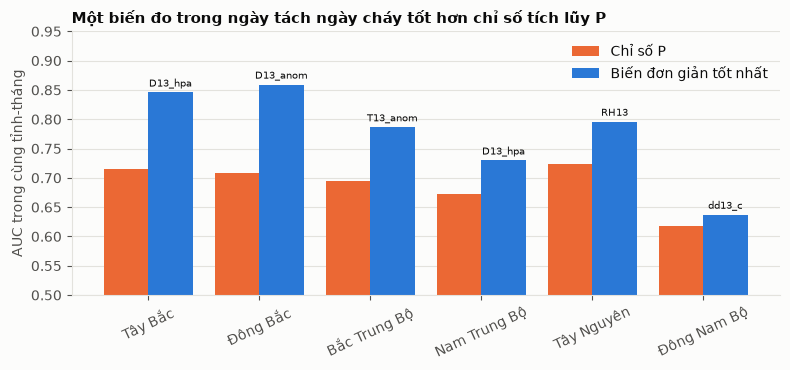

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(FOREST))
ax.bar(x - 0.2, compare["P (Nesterov)"], 0.4, color=ORANGE, label="Chỉ số P")
ax.bar(x + 0.2, compare["biến đơn giản tốt nhất"], 0.4, color=BLUE, label="Biến đơn giản tốt nhất")
for i, name in enumerate(compare["tên biến"]):
    ax.text(i + 0.2, compare["biến đơn giản tốt nhất"].iloc[i] + 0.01, name, ha="center", fontsize=7.5, color=INK)
ax.set_xticks(x)
ax.set_xticklabels(compare.index, rotation=25)
ax.set_ylim(0.5, 0.95)
ax.set_ylabel("AUC trong cùng tỉnh-tháng")
ax.set_title("Một biến đo trong ngày tách ngày cháy tốt hơn chỉ số tích lũy P")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
strength.loc[["D13_hpa", "D13_anom", "RH13", "T13", "rain_3d", "dsr_1", "P_primary"]].round(3).T

Ở cả sáu vùng, ít nhất một biến đo trong ngày (độ hụt bão hòa, độ ẩm, nhiệt độ hoặc mưa 3 ngày) tách ngày cháy tốt hơn chỉ số P. Khoảng cách lớn nhất ở Đông Bắc và Tây Bắc, nơi độ hụt bão hòa 13h đạt khoảng 0,85 so với 0,71 đến 0,72 của P; nhỏ nhất ở Nam Trung Bộ (0,73 so với 0,67). Đông Nam Bộ là vùng khó nhất, không biến nào vượt quá khoảng 0,64. Câu hỏi tiếp theo là vì sao một chỉ số tích lũy lại thua một đại lượng đo trong ngày.

Chương 2. Vì sao P yếu: khô kéo dài hơn một tuần không làm cháy dễ hơn, và mưa nhỏ đã đủ dập cháy. Đầu tiên xem xác suất cháy theo số ngày kể từ lần mưa lớn gần nhất.

region,TB,DB,BTB,NTB,TN,DNB
dsr_bin,,,,,,
0,25.0,12.0,22.0,27.0,45.0,20.0
1-2,26.0,10.0,34.0,34.0,56.0,28.0
3-5,46.0,23.0,54.0,49.0,66.0,34.0
6-10,57.0,32.0,60.0,54.0,66.0,35.0
11-20,59.0,37.0,61.0,58.0,64.0,34.0
21-40,53.0,34.0,63.0,61.0,71.0,39.0
>40,61.0,34.0,60.0,76.0,92.0,47.0


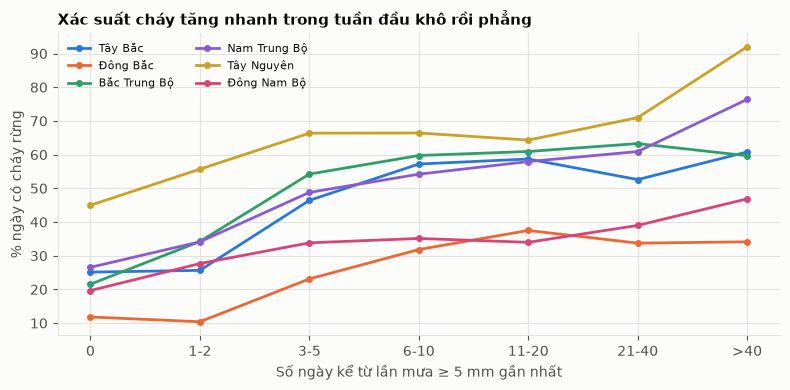

In [4]:
edges = [-1, 0, 2, 5, 10, 20, 40, 1e9]
labels = ["0", "1-2", "3-5", "6-10", "11-20", "21-40", ">40"]
sample["dsr_bin"] = pd.cut(sample["dsr_5"], edges, labels=labels)
curve = sample.pivot_table(index="dsr_bin", columns="region", values="fire_any_forest", aggfunc="mean", observed=True)[FOREST] * 100

fig, ax = plt.subplots(figsize=(8, 4))
for color, region in zip(PALETTE, FOREST):
    ax.plot(range(len(labels)), curve[region].values, marker="o", ms=4, lw=2, color=color, label=VN[region])
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_xlabel("Số ngày kể từ lần mưa ≥ 5 mm gần nhất")
ax.set_ylabel("% ngày có cháy rừng")
ax.set_title("Xác suất cháy tăng nhanh trong tuần đầu khô rồi phẳng")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
curve.round(0)

Xác suất cháy tăng mạnh trong khoảng 3 đến 5 ngày đầu sau cơn mưa rồi gần như phẳng (Bắc Trung Bộ từ 22% lên 54% rồi dừng ở khoảng 60 đến 63%; Tây Bắc và Đông Bắc phẳng sau 6 đến 10 ngày). Hạn kéo dài thêm vài tuần không làm cháy dễ hơn, nên một chỉ số tích lũy như P cho thêm rất ít thông tin sau tuần đầu. Tây Nguyên là ngoại lệ, vẫn tăng ở mức hạn rất dài. Câu hỏi thứ hai: quy tắc của P coi mưa từ 5 mm là đặt lại về 0, vậy mưa nhỏ hơn có dập cháy không? Giả thuyết: lượng mưa đủ dập cháy khác nhau giữa các vùng và có thể thấp hơn 5 mm. Thiết kế: chọn các ngày có mưa sau ít nhất ba ngày khô liền, so tỉ lệ cháy ở các ngày sau với nhóm không mưa trong cùng vùng, tháng và mức độ khô của ngày hôm trước.

In [5]:
CLASSES = ["[1,2)", "[2,5)", "[5,10)", "≥10"]
EDGES = [0, 1, 2, 5, 10, np.inf]
HORIZONS = [0, 1, 2, 3, 5, 7]

for k in range(0, 8):
    ordered[f"out{k}"] = by_prov["fire_any_forest"].shift(-k)
for k in (1, 2, 3):
    ordered[f"rain_prev{k}"] = by_prov["rain_cal"].shift(k)
ordered["pre_D13"] = by_prov["D13_hpa"].shift(1)

events = ordered[
    (ordered["analysis_sample"] == 1)
    & (ordered[["rain_prev1", "rain_prev2", "rain_prev3"]] < 1).all(axis=1)
    & ordered["pre_D13"].notna()
    & ordered["out7"].notna()
].copy()
events["rain_class"] = pd.cut(events["rain_cal"], EDGES, right=False, labels=["<1"] + CLASSES)
events["quintile"] = events.groupby(["region", "month"])["pre_D13"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
events["stratum"] = pd.factorize(events["region"].astype(str) + "|" + events["month"].astype(str) + "|" + events["quintile"].astype(str))[0]
events["season"] = events["season"].astype(int)
print("Ngày mưa sau ba ngày khô:", len(events))
events.groupby(["region", "rain_class"], observed=True).size().unstack().reindex(FOREST)

Ngày mưa sau ba ngày khô: 38541


rain_class,<1,"[1,2)","[2,5)","[5,10)",≥10
region,,,,,
TB,3957,261,246,121,91
DB,7538,712,703,295,133
BTB,1928,280,266,135,107
NTB,5579,583,502,175,81
TN,6272,244,204,86,68
DNB,7307,276,253,93,45


In [6]:
def class_effect(frame, cls, horizon, weights=None):
    sub = frame[frame["rain_class"].isin(["<1", cls])]
    stratum = sub["stratum"].values
    n_strata = frame["stratum"].max() + 1
    flag = (sub["rain_class"] == cls).values.astype(float)
    y = sub[f"out{horizon}"].values
    w = np.ones(len(sub)) if weights is None else weights[sub["season_pos"].values]
    n1 = np.bincount(stratum, flag * w, n_strata)
    n0 = np.bincount(stratum, (1 - flag) * w, n_strata)
    r1 = np.bincount(stratum, flag * w * y, n_strata)
    r0 = np.bincount(stratum, (1 - flag) * w * y, n_strata)
    ok = (n1 > 0) & (n0 > 0)
    if not ok.any():
        return np.nan
    return np.sum(n1[ok] * (r1[ok] / n1[ok] - r0[ok] / n0[ok])) / np.sum(n1[ok]) * 100


events["season_pos"] = pd.factorize(events["season"])[0]
n_seasons = events["season_pos"].max() + 1
rng = np.random.default_rng(0)
draws = [np.bincount(rng.integers(0, n_seasons, n_seasons), minlength=n_seasons).astype(float) for _ in range(500)]

rows = []
for region in FOREST:
    part = events[events["region"] == region]
    for cls in CLASSES:
        for k in HORIZONS:
            point = class_effect(part, cls, k)
            boots = np.array([class_effect(part, cls, k, d) for d in draws])
            rows.append({"region": region, "class": cls, "k": k, "effect": point, "lo": np.nanpercentile(boots, 2.5), "hi": np.nanpercentile(boots, 97.5)})
effects = pd.DataFrame(rows)

table = effects[effects["k"].isin([1, 3])].pivot_table(index=["region", "k"], columns="class", values="effect")[CLASSES].reindex(FOREST, level=0)
table.index = pd.MultiIndex.from_tuples([(VN[r], f"ngày +{k}") for r, k in table.index])
print("Tỉ lệ cháy so với ngày không mưa (điểm phần trăm), sau cơn mưa theo lượng mưa")
table.round(1)

Tỉ lệ cháy so với ngày không mưa (điểm phần trăm), sau cơn mưa theo lượng mưa


class                 [1,2)  [2,5)  [5,10)   ≥10
Tây Bắc      ngày +1  -17.9  -31.9   -39.6 -46.3
             ngày +3  -12.1  -18.4   -23.9 -33.6
Đông Bắc     ngày +1  -16.7  -19.5   -30.3 -35.0
             ngày +3  -12.7  -14.5   -17.4 -23.2
Bắc Trung Bộ ngày +1   -4.0  -12.0   -39.4 -50.7
             ngày +3   -6.0   -6.1   -11.9 -17.4
Nam Trung Bộ ngày +1  -10.6  -22.4   -34.4 -44.3
             ngày +3   -7.1  -10.3   -14.1 -21.3
Tây Nguyên   ngày +1   -6.8  -15.1   -21.4 -26.2
             ngày +3   -8.3  -13.0   -21.9 -16.3
Đông Nam Bộ  ngày +1  -13.8  -15.6   -22.4 -19.2
             ngày +3   -4.9   -2.2   -11.1 -10.3

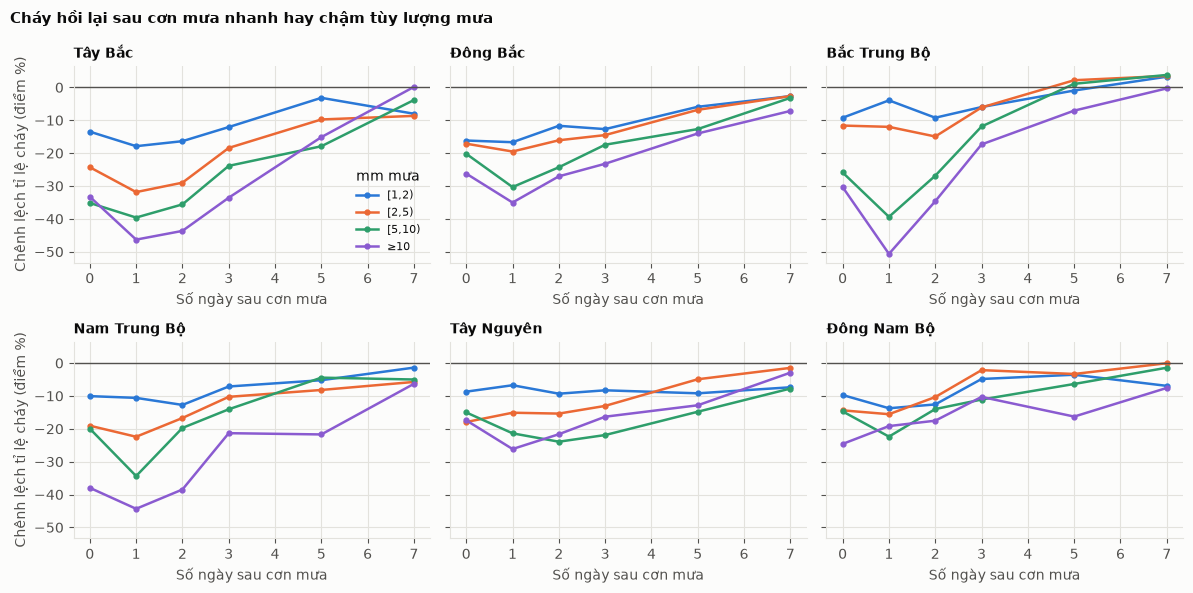

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, region in zip(axes.ravel(), FOREST):
    for color, cls in zip(PALETTE, CLASSES):
        g = effects[(effects["region"] == region) & (effects["class"] == cls)]
        ax.plot(g["k"], g["effect"], marker="o", ms=3.5, lw=1.8, color=color, label=cls)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(VN[region], fontsize=10)
    ax.set_xlabel("Số ngày sau cơn mưa")
for ax in axes[:, 0]:
    ax.set_ylabel("Chênh lệch tỉ lệ cháy (điểm %)")
axes[0, 0].legend(frameon=False, fontsize=8, title="mm mưa")
fig.suptitle("Cháy hồi lại sau cơn mưa nhanh hay chậm tùy lượng mưa", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()

In [8]:
ratio = effects[(effects["k"] == 1)].pivot_table(index="region", columns="class", values="effect")[CLASSES].reindex(FOREST)
share = ratio.div(ratio["≥10"], axis=0)[CLASSES[:-1]]
share.index = [VN[r] for r in share.index]
print("Tác dụng dập cháy ở ngày +1 của từng mức mưa, so với mưa từ 10 mm trở lên (1,0 là bằng)")
share.round(2)

Tác dụng dập cháy ở ngày +1 của từng mức mưa, so với mưa từ 10 mm trở lên (1,0 là bằng)


class,"[1,2)","[2,5)","[5,10)"
Tây Bắc,0.39,0.69,0.86
Đông Bắc,0.48,0.56,0.87
Bắc Trung Bộ,0.08,0.24,0.78
Nam Trung Bộ,0.24,0.51,0.78
Tây Nguyên,0.26,0.58,0.82
Đông Nam Bộ,0.72,0.81,1.17


In [9]:
def half_table(frame, horizon):
    out = {}
    for name, mask in [("nửa thăm dò (đến 2018)", frame["season"] <= SPLIT_SEASON), ("nửa xác nhận (từ 2019)", frame["season"] > SPLIT_SEASON)]:
        part = frame[mask]
        out[name] = {cls: class_effect(part, cls, horizon) for cls in ["[2,5)", "[5,10)", "≥10"]}
    return pd.DataFrame(out).T


rows = []
for region in FOREST:
    part = events[events["region"] == region]
    for k in (1, 3):
        h = half_table(part, k)
        for half, row in h.iterrows():
            rows.append({"region": VN[region], "ngày": f"+{k}", "nửa": half, **row.to_dict()})
pd.DataFrame(rows).set_index(["region", "ngày", "nửa"]).round(1)

[2,5)  [5,10)   ≥10
region       ngày nửa                                        
Tây Bắc      +1   nửa thăm dò (đến 2018)  -31.8   -44.1 -41.2
                  nửa xác nhận (từ 2019)  -31.5   -32.3 -51.1
             +3   nửa thăm dò (đến 2018)  -18.3   -23.4 -30.8
                  nửa xác nhận (từ 2019)  -16.4   -23.3 -37.2
Đông Bắc     +1   nửa thăm dò (đến 2018)  -16.9   -28.4 -31.5
                  nửa xác nhận (từ 2019)  -22.5   -32.7 -35.8
             +3   nửa thăm dò (đến 2018)  -10.9   -15.2 -19.7
                  nửa xác nhận (từ 2019)  -15.9   -17.2 -21.8
Bắc Trung Bộ +1   nửa thăm dò (đến 2018)  -15.0   -44.3 -50.9
                  nửa xác nhận (từ 2019)   -9.5   -35.0 -51.4
             +3   nửa thăm dò (đến 2018)  -11.0   -16.0 -16.1
                  nửa xác nhận (từ 2019)   -2.4    -4.9 -14.7
Nam Trung Bộ +1   nửa thăm dò (đến 2018)  -26.4   -44.0 -48.6
                  nửa xác nhận (từ 2019)  -19.0   -27.9 -37.4
             +3   nửa thăm dò (đến 2018)  -15.5   -20.6 -22.1
                  nửa xác nhận (từ 2019)   -6.4    -8.8 -19.4
Tây Nguyên   +1   nửa thăm dò (đến 2018)  -11.8   -32.2 -29.8
                  nửa xác nhận (từ 2019)  -15.0    -9.4 -20.2
             +3   nửa thăm dò (đến 2018)  -14.2   -29.4 -15.1
                  nửa xác nhận (từ 2019)  -13.5   -15.6 -25.0
Đông Nam Bộ  +1   nửa thăm dò (đến 2018)  -14.2   -16.1 -23.6
                  nửa xác nhận (từ 2019)  -15.4   -28.8 -11.4
             +3   nửa thăm dò (đến 2018)    4.4    -3.3  -2.6
                  nửa xác nhận (từ 2019)   -8.6   -19.8 -19.2

Giả thuyết được ủng hộ một phần. Tỉ lệ cháy giảm theo lượng mưa ở mọi vùng và cơn mưa dưới 5 mm đã có tác dụng đáng kể: mưa 2 đến 5 mm đạt 69% tác dụng của mưa từ 10 mm trở lên ở Tây Bắc, 56% ở Đông Bắc, 58% ở Tây Nguyên, 51% ở Nam Trung Bộ và 81% ở Đông Nam Bộ (ngày +1), tức ngưỡng thực tế thấp hơn 5 mm. Bắc Trung Bộ là ngoại lệ, mưa dưới 5 mm chỉ đạt 24% tác dụng, nên ngưỡng 5 mm ở đó khá hợp lý. Đối chiếu hai nửa thời gian cho cùng dấu ở gần như mọi ô nhưng độ lớn dao động nhiều, nên chỉ tin xu hướng chung. Lưu ý quan trọng: biến kết quả là điểm cháy do vệ tinh ghi nhận, ngày mưa nhiều mây nên vệ tinh khó phát hiện cháy, do đó các con số là cận trên của tác dụng dập cháy thật, và đây là mối liên hệ chưa phải quan hệ nhân quả.

Chương 3. Vì sao P không dùng chung được: ngưỡng độ khô để cháy bắt đầu khác nhau gấp đôi giữa các vùng. Giả thuyết: ngưỡng độ hụt bão hòa (mức tại đó tỉ lệ cháy đạt nửa mức bão hòa của tỉnh) và độ dài trí nhớ về mưa khác nhau giữa các tỉnh theo độ cao, độ phủ rừng và vĩ độ.

In [10]:
def half_saturation(frame):
    bins = pd.qcut(frame["D13_hpa"], 10, duplicates="drop")
    rate = frame.groupby(bins)["fire_any_forest"].mean()
    x = frame.groupby(bins)["D13_hpa"].mean()
    target = (rate.min() + rate.max()) / 2
    hit = np.where(rate.values >= target)[0][0]
    if hit == 0:
        return x.iloc[0]
    x0, x1, y0, y1 = x.iloc[hit - 1], x.iloc[hit], rate.iloc[hit - 1], rate.iloc[hit]
    return x0 + (target - y0) / (y1 - y0) * (x1 - x0)


def strength_within_month(frame, column):
    scores = []
    for _, cell in frame.groupby("month"):
        if cell["fire_any_forest"].nunique() > 1 and len(cell) > 30:
            auc = roc_auc_score(cell["fire_any_forest"], cell[column])
            scores.append((abs(auc - 0.5) + 0.5, len(cell)))
    scores = np.array(scores)
    return np.average(scores[:, 0], weights=scores[:, 1])


def province_table(frame):
    rows = {}
    for prov, g in frame.groupby("prov"):
        rows[prov] = {
            "ngưỡng khô (hPa)": half_saturation(g),
            "trí nhớ mưa": strength_within_month(g, "rain_30d") - strength_within_month(g, "rain_3d"),
        }
    return pd.DataFrame(rows).T


attributes = sample.groupby("prov").agg(region=("region", "first"), độ_cao=("rep_elev_m", "first"), rừng=("forest_share", "first"), nông_nghiệp=("crop_share", "first"), vĩ_độ=("rep_lat", "first"))
full = province_table(sample).join(attributes)
early_half = province_table(sample[sample["season"] <= SPLIT_SEASON]).join(attributes)
late_half = province_table(sample[sample["season"] > SPLIT_SEASON]).join(attributes)

reliability = {c: spearmanr(early_half[c], late_half[c])[0] for c in ["ngưỡng khô (hPa)", "trí nhớ mưa"]}
print("Độ ổn định giữa hai nửa thời gian của ước lượng theo tỉnh (Spearman):", {k: round(v, 2) for k, v in reliability.items()})
full.groupby("region")[["ngưỡng khô (hPa)", "trí nhớ mưa"]].agg(["mean", "std"]).reindex(FOREST).round(2)

Độ ổn định giữa hai nửa thời gian của ước lượng theo tỉnh (Spearman): {'ngưỡng khô (hPa)': np.float64(0.82), 'trí nhớ mưa': np.float64(0.77)}


ngưỡng khô (hPa)       trí nhớ mưa      
                   mean   std        mean   std
region                                         
TB                 9.83  1.84       -0.17  0.02
DB                10.80  1.46       -0.14  0.04
BTB               17.06  3.94       -0.13  0.04
NTB               11.75  2.71       -0.08  0.04
TN                12.74  2.03       -0.06  0.02
DNB               19.04  3.74       -0.04  0.01

In [11]:
def holm(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted


rows = []
for outcome in ["ngưỡng khô (hPa)", "trí nhớ mưa"]:
    for attribute in ["độ_cao", "rừng", "nông_nghiệp", "vĩ_độ"]:
        rho, p = spearmanr(full[outcome], full[attribute])
        rho_e, _ = spearmanr(early_half[outcome], early_half[attribute])
        rho_l, _ = spearmanr(late_half[outcome], late_half[attribute])
        rows.append({"kết quả": outcome, "thuộc tính": attribute, "rho": rho, "p": p, "rho nửa thăm dò": rho_e, "rho nửa xác nhận": rho_l})
determinants = pd.DataFrame(rows)
determinants["p Holm"] = holm(determinants["p"])
determinants.set_index(["kết quả", "thuộc tính"]).round(3)

rho      p  rho nửa thăm dò  rho nửa xác nhận  p Holm
kết quả          thuộc tính                                                          
ngưỡng khô (hPa) độ_cao      -0.469  0.002           -0.455            -0.398   0.014
                 rừng        -0.298  0.062           -0.253            -0.353   0.186
                 nông_nghiệp  0.441  0.004            0.386             0.391   0.018
                 vĩ_độ       -0.542  0.000           -0.530            -0.612   0.002
trí nhớ mưa      độ_cao      -0.114  0.484           -0.088            -0.126   0.968
                 rừng        -0.455  0.003           -0.402            -0.479   0.016
                 nông_nghiệp -0.039  0.811            0.013            -0.018   0.968
                 vĩ_độ       -0.718  0.000           -0.634            -0.726   0.000

Giả thuyết được ủng hộ. Ngưỡng độ hụt bão hòa để cháy bắt đầu khác nhau gần gấp đôi giữa các vùng (Tây Bắc 9,8, Đông Bắc 10,8, Nam Trung Bộ 11,8, Tây Nguyên 12,7, Bắc Trung Bộ 17,1, Đông Nam Bộ 19,0 hPa): một mức khô làm cháy bắt đầu ở Tây Bắc thì chưa đủ ở Đông Nam Bộ. Ngưỡng thấp hơn ở tỉnh cao hơn (rho −0,47, Holm 0,014) và vĩ độ cao hơn (−0,54, Holm 0,002), cao hơn ở tỉnh nhiều đất nông nghiệp (+0,44, Holm 0,018). Trí nhớ về mưa cũng đổi theo vĩ độ (−0,72) và độ phủ rừng (−0,46): ở phía Bắc chỉ mưa vài ngày gần nhất có ý nghĩa, ở phía Nam lượng mưa tích lũy cả tháng gần như quan trọng ngang mưa ba ngày gần đây. Ước lượng theo tỉnh ổn định giữa hai nửa thời gian (Spearman 0,82 và 0,77) và các hệ số tương quan giữ cùng dấu và độ lớn. Lưu ý: độ cao, vĩ độ, tỉ lệ rừng và nông nghiệp tương quan với nhau và chỉ có 40 tỉnh, nên không tách được thuộc tính nào là nguyên nhân. Đây là một lý do trực tiếp khiến một thang P chung không dùng được cho cả nước.

Chương 4. Cháy là chuyện của các đợt, không chỉ của thời tiết. Có bốn bằng chứng. Thứ nhất, hôm qua có cháy thì hôm nay cháy cao hơn nhiều dù đã so ở cùng mức độ khô.

In [12]:
ordered = df.sort_values(["prov", "date"]).reset_index(drop=True)
grouped = ordered.groupby("prov")["fire_any_forest"]
ordered["fire_lag1"] = grouped.shift(1)
ordered["fire_prev3"] = sum(grouped.shift(k) for k in (1, 2, 3))
persist = ordered[ordered["analysis_sample"] == 1].dropna(subset=["fire_lag1", "fire_prev3"]).copy()
persist["dryness"] = persist.groupby("region")["D13_anom"].transform(lambda s: pd.qcut(s, 3, labels=["ít khô", "khô vừa", "rất khô"]))

by_dryness = persist.pivot_table(index=["region", "dryness"], columns="fire_lag1", values="fire_any_forest", aggfunc="mean", observed=True) * 100
by_dryness.columns = ["hôm qua không cháy", "hôm qua có cháy"]
by_dryness["chênh lệch"] = by_dryness["hôm qua có cháy"] - by_dryness["hôm qua không cháy"]
by_dryness = by_dryness.reindex(FOREST, level=0)
by_dryness.index = pd.MultiIndex.from_tuples([(VN[r], d) for r, d in by_dryness.index])
print("% ngày có cháy hôm nay, theo độ khô trong ngày (chia ba mức trong từng vùng) và việc hôm qua có cháy")
by_dryness.round(0)

% ngày có cháy hôm nay, theo độ khô trong ngày (chia ba mức trong từng vùng) và việc hôm qua có cháy


hôm qua không cháy  hôm qua có cháy  chênh lệch
Tây Bắc      ít khô                  8.0             49.0        41.0
             khô vừa                25.0             68.0        43.0
             rất khô                54.0             90.0        36.0
Đông Bắc     ít khô                  2.0             20.0        18.0
             khô vừa                10.0             35.0        25.0
             rất khô                40.0             76.0        36.0
Bắc Trung Bộ ít khô                 11.0             32.0        21.0
             khô vừa                34.0             60.0        25.0
             rất khô                52.0             76.0        24.0
Nam Trung Bộ ít khô                 15.0             53.0        38.0
             khô vừa                29.0             74.0        45.0
             rất khô                38.0             79.0        41.0
Tây Nguyên   ít khô                 24.0             78.0        54.0
             khô vừa                35.0             85.0        50.0
             rất khô                55.0             92.0        37.0
Đông Nam Bộ  ít khô                 20.0             46.0        26.0
             khô vừa                26.0             51.0        25.0
             rất khô                34.0             58.0        24.0

In [13]:
onset = persist[persist["fire_prev3"] == 0].pivot_table(index="region", columns="dryness", values="fire_any_forest", aggfunc="mean", observed=True).reindex(FOREST) * 100
onset.index = [VN[r] for r in onset.index]
print("% ngày bắt đầu cháy mới (3 ngày trước không có cháy), theo độ khô trong ngày")
onset.round(0)

% ngày bắt đầu cháy mới (3 ngày trước không có cháy), theo độ khô trong ngày


dryness,ít khô,khô vừa,rất khô
Tây Bắc,6.0,20.0,49.0
Đông Bắc,2.0,9.0,35.0
Bắc Trung Bộ,8.0,29.0,46.0
Nam Trung Bộ,9.0,21.0,25.0
Tây Nguyên,13.0,25.0,43.0
Đông Nam Bộ,14.0,20.0,25.0


Chênh lệch này vẫn còn khi so ở cùng mức độ khô: ở mức rất khô vẫn chênh 24 đến 41 điểm phần trăm tùy vùng (Tây Bắc 36, Đông Bắc 36, Bắc Trung Bộ 24, Nam Trung Bộ 41, Tây Nguyên 37, Đông Nam Bộ 24), nên quán tính cháy không chỉ là hệ quả của thời tiết giống nhau giữa hai ngày liền. Với ngày bắt đầu cháy mới, xác suất tăng mạnh theo độ khô ở Tây Bắc, Đông Bắc, Bắc Trung Bộ và Tây Nguyên nhưng tăng ít ở Nam Trung Bộ và Đông Nam Bộ, tức ở hai vùng sau thời tiết trong ngày ít phân biệt được ngày bắt đầu cháy. Thứ hai, giả thuyết cạn nhiên liệu: đã cháy nhiều trong mùa thì ngày sau cháy ít đi. Đo mức đã cháy bằng tổng số điểm cháy đến hôm qua chia cho mức trung bình cả mùa của tỉnh, so nhóm cháy nhiều nhất với nhóm ít nhất trong cùng vùng, tháng, độ khô và trạng thái hôm qua.

In [14]:
ordered = df.sort_values(["prov", "date"]).reset_index(drop=True)
ordered["fire_yesterday"] = ordered.groupby("prov")["fire_any_forest"].shift(1)
sorted_sample = ordered[ordered["analysis_sample"] == 1].copy()
sorted_sample["season"] = sorted_sample["season"].astype(int)
sorted_sample["burned_before"] = sorted_sample.groupby(["prov", "season"])["n_hot_forest"].cumsum() - sorted_sample["n_hot_forest"]
season_total = sorted_sample.groupby(["prov", "season"])["n_hot_forest"].sum().rename("season_total")
province_mean = season_total.groupby("prov").mean().rename("province_mean")
sorted_sample = sorted_sample.join(province_mean, on="prov")
sorted_sample["progress"] = sorted_sample["burned_before"] / sorted_sample["province_mean"]
sorted_sample = sorted_sample.dropna(subset=["fire_yesterday"])
sorted_sample["quintile"] = sorted_sample.groupby(["region", "month"])["D13_hpa"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
sorted_sample["stratum"] = pd.factorize(sorted_sample["region"].astype(str) + "|" + sorted_sample["month"].astype(str) + "|" + sorted_sample["quintile"].astype(str) + "|" + sorted_sample["fire_yesterday"].astype(str))[0]
sorted_sample["tertile"] = sorted_sample.groupby("stratum")["progress"].transform(lambda s: pd.qcut(s.rank(method="first"), 3, labels=False) if len(s) >= 30 else np.nan)
valid = sorted_sample.dropna(subset=["tertile"]).copy()
valid["season_pos"] = pd.factorize(valid["season"])[0]
n_strata = valid["stratum"].max() + 1


def depletion_effect(frame, weights=None):
    top = (frame["tertile"] == 2).values.astype(float)
    bottom = (frame["tertile"] == 0).values.astype(float)
    y = frame["fire_any_forest"].values
    w = np.ones(len(frame)) if weights is None else weights[frame["season_pos"].values]
    stratum = frame["stratum"].values
    n1 = np.bincount(stratum, top * w, n_strata)
    n0 = np.bincount(stratum, bottom * w, n_strata)
    r1 = np.bincount(stratum, top * w * y, n_strata)
    r0 = np.bincount(stratum, bottom * w * y, n_strata)
    ok = (n1 > 0) & (n0 > 0)
    return np.sum(n1[ok] * (r1[ok] / n1[ok] - r0[ok] / n0[ok])) / np.sum(n1[ok]) * 100


n_seasons = valid["season_pos"].max() + 1
rng = np.random.default_rng(0)
draws = [np.bincount(rng.integers(0, n_seasons, n_seasons), minlength=n_seasons).astype(float) for _ in range(500)]
rows = []
for region in FOREST + ["all"]:
    part = valid if region == "all" else valid[valid["region"] == region]
    boots = np.array([depletion_effect(part, d) for d in draws])
    early, late = part[part["season"] <= SPLIT_SEASON], part[part["season"] > SPLIT_SEASON]
    rows.append({
        "vùng": "tất cả" if region == "all" else VN[region], "chênh lệch (điểm %)": depletion_effect(part),
        "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
        "nửa thăm dò": depletion_effect(early), "nửa xác nhận": depletion_effect(late),
    })
pd.DataFrame(rows).set_index("vùng").round(2)

,chênh lệch (điểm %),ci_lo,ci_hi,nửa thăm dò,nửa xác nhận
vùng,,,,,
Tây Bắc,2.58,-0.07,5.77,3.40,1.00
Đông Bắc,2.66,0.93,4.59,3.09,-0.00
Bắc Trung Bộ,0.93,-2.83,3.85,-0.66,-2.49
Nam Trung Bộ,7.15,3.01,10.13,7.93,5.96
Tây Nguyên,14.48,11.80,15.92,13.33,14.95
Đông Nam Bộ,6.65,0.90,11.12,8.86,4.90
tất cả,5.53,3.74,7.10,6.10,3.26


Giả thuyết cạn nhiên liệu bị bác bỏ, và kết quả đi ngược hẳn: ở cùng độ khô và cùng trạng thái hôm qua, nhóm đã cháy nhiều trong mùa có xác suất cháy cao hơn nhóm đã cháy ít khoảng 5,5 điểm phần trăm (khoảng tin cậy 95% từ 3,7 đến 7,1), nhiều nhất ở Tây Nguyên (+14,5), rồi Nam Trung Bộ (+7,2) và Đông Nam Bộ (+6,7); Bắc Trung Bộ không có ý nghĩa. Dấu dương giữ ở cả hai nửa thời gian ở toàn bộ mẫu và ở Tây Bắc, Nam Trung Bộ, Tây Nguyên, Đông Nam Bộ; Đông Bắc về 0 ở nửa xác nhận. Tức mùa cháy có đà: những tỉnh-mùa đã cháy nhiều tiếp tục cháy nhiều, vượt cả phần do độ khô và hôm qua giải thích. Chưa phân biệt được đà đó do độ khô tích lũy không đo được, do hoạt động của con người hay do điều kiện nhiên liệu. Thứ ba, cháy tập trung vào rất ít ngày.

In [15]:
def concentration(frame):
    rows = {}
    for region in FOREST:
        counts = frame.loc[frame["region"] == region, "n_hot_forest"].sort_values(ascending=False).values
        total = counts.sum()
        n = len(counts)
        cum = np.cumsum(counts) / total
        lorenz = np.cumsum(np.sort(counts)) / total
        gini = 1 - 2 * lorenz.mean() + 1 / n
        rows[VN[region]] = {
            "% ngày có cháy": (counts > 0).mean() * 100,
            "% điểm cháy ở 1% ngày": cum[int(n * 0.01) - 1] * 100,
            "% điểm cháy ở 5% ngày": cum[int(n * 0.05) - 1] * 100,
            "% điểm cháy ở 10% ngày": cum[int(n * 0.10) - 1] * 100,
            "Gini": gini,
        }
    return pd.DataFrame(rows).T


conc_all = concentration(sample)
conc_early = concentration(sample[sample["season"] <= SPLIT_SEASON])
conc_late = concentration(sample[sample["season"] > SPLIT_SEASON])
print("Toàn bộ mẫu")
display(conc_all.round(1))
print("% điểm cháy ở 5% ngày: nửa thăm dò so với nửa xác nhận")
pd.DataFrame({"thăm dò": conc_early["% điểm cháy ở 5% ngày"], "xác nhận": conc_late["% điểm cháy ở 5% ngày"]}).round(1)

Toàn bộ mẫu


,% ngày có cháy,% điểm cháy ở 1% ngày,% điểm cháy ở 5% ngày,% điểm cháy ở 10% ngày,Gini
Tây Bắc,47.5,20.6,56.7,76.1,0.9
Đông Bắc,25.2,25.7,61.0,80.2,0.9
Bắc Trung Bộ,42.5,23.6,54.1,71.0,0.8
Nam Trung Bộ,46.6,16.1,42.7,61.4,0.8
Tây Nguyên,70.2,9.4,31.2,48.8,0.7
Đông Nam Bộ,35.6,13.0,37.7,57.1,0.8


% điểm cháy ở 5% ngày: nửa thăm dò so với nửa xác nhận


,thăm dò,xác nhận
Tây Bắc,55.6,54.9
Đông Bắc,62.8,59.4
Bắc Trung Bộ,54.8,46.8
Nam Trung Bộ,43.9,41.0
Tây Nguyên,27.3,34.3
Đông Nam Bộ,37.7,37.6


In [16]:
lagged = df.sort_values(["prov", "date"]).assign(fire_yesterday=lambda x: x.groupby("prov")["fire_any_forest"].shift(1))[["prov", "date", "fire_yesterday"]]
rows = {}
for region in FOREST:
    a = sample[sample["region"] == region].merge(lagged, on=["prov", "date"], how="left")
    threshold = a["n_hot_forest"].quantile(0.99)
    top = a[a["n_hot_forest"] >= threshold]
    percentile = a["D13_hpa"].rank(pct=True)
    rows[VN[region]] = {
        "ngưỡng điểm/ngày của 1% ngày lớn nhất": threshold,
        "số ngày": len(top),
        "độ khô trung bình của nhóm đó (phân vị)": percentile[top.index].mean() * 100,
        "% có cháy hôm qua": top["fire_yesterday"].mean() * 100,
        "% có cháy hôm qua, mọi ngày": a["fire_yesterday"].mean() * 100,
    }
pd.DataFrame(rows).T.round(1)

,ngưỡng điểm/ngày của 1% ngày lớn nhất,số ngày,độ khô trung bình của nhóm đó (phân vị),% có cháy hôm qua,"% có cháy hôm qua, mọi ngày"
Tây Bắc,125.0,98.0,94.6,100.0,47.5
Đông Bắc,22.0,284.0,84.4,93.0,25.1
Bắc Trung Bộ,38.0,133.0,80.1,94.7,42.7
Nam Trung Bộ,32.0,260.0,77.4,98.1,46.4
Tây Nguyên,69.0,126.0,77.4,100.0,69.9
Đông Nam Bộ,8.0,149.0,76.8,80.5,35.5


Cháy tập trung rất mạnh: 5% số ngày-tỉnh lớn nhất chứa từ 31% (Tây Nguyên) đến 61% (Đông Bắc) số điểm cháy, 1% ngày lớn nhất chứa 9% đến 26%, hệ số Gini từ 0,7 đến 0,9, và con số này giữ gần như nguyên giữa hai nửa thời gian. Những ngày lớn nhất khô hơn bình thường (phân vị độ khô trung bình từ 77 đến 95) nhưng không phải ngày khô nhất, và hầu như đều là ngày tiếp nối cháy hôm qua (93% đến 100% ở năm vùng, 81% ở Đông Nam Bộ, so với 25% đến 70% với mọi ngày). Những ngày cháy cực lớn nằm trong các đợt cháy kéo dài, không phải những đợt bùng phát đơn lẻ. Thứ tư, cháy của các tỉnh gần nhau đồng bộ với nhau ngoài phần do thời tiết giải thích.

In [17]:
sample["quintile"] = sample.groupby(["region", "month"])["D13_hpa"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
sample["stratum"] = sample["region"].astype(str) + "|" + sample["month"].astype(str) + "|" + sample["quintile"].astype(str)
sample["expected"] = sample.groupby("stratum")["fire_any_forest"].transform("mean")
sample["resid"] = (sample["fire_any_forest"] - sample["expected"]) * 100

In [18]:
residuals = sample.pivot_table(index="date", columns="prov", values="resid")
coords = sample.groupby("prov")[["rep_lat", "rep_lon"]].first()


def haversine(a, b):
    a, b = np.asarray(a), np.asarray(b)
    la1, lo1, la2, lo2 = map(np.radians, [a[0], a[1], b[0], b[1]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))


def pair_table(frame):
    corr = frame.corr(min_periods=300)
    rows = []
    provs = list(corr.columns)
    for i, p in enumerate(provs):
        for q in provs[i + 1:]:
            if np.isnan(corr.loc[p, q]):
                continue
            rows.append({"a": p, "b": q, "corr": corr.loc[p, q], "km": haversine(coords.loc[p], coords.loc[q]), "cùng vùng": region_of[p] == region_of[q]})
    return pd.DataFrame(rows)


pairs = pair_table(residuals)
pairs["nhóm km"] = pd.cut(pairs["km"], [0, 100, 200, 400, 800, 3000], labels=["0-100", "100-200", "200-400", "400-800", ">800"])
print("Số cặp tỉnh:", len(pairs))
by_distance = pairs.pivot_table(index="nhóm km", columns="cùng vùng", values="corr", aggfunc=["mean", "count"], observed=True)
by_distance.round(3)

Số cặp tỉnh: 780


mean         count      
cùng vùng  False  True   False True 
nhóm km                             
0-100      0.175  0.236   13.0  38.0
100-200    0.123  0.200   55.0  48.0
200-400    0.093  0.137  115.0  35.0
400-800    0.045  0.064  182.0   8.0
>800       0.028    NaN  286.0   NaN

Toàn bộ: Spearman giữa khoảng cách và tương quan = -0.65 (p = 4.62e-95)
Nửa thăm dò: -0.62 | nửa xác nhận: -0.61


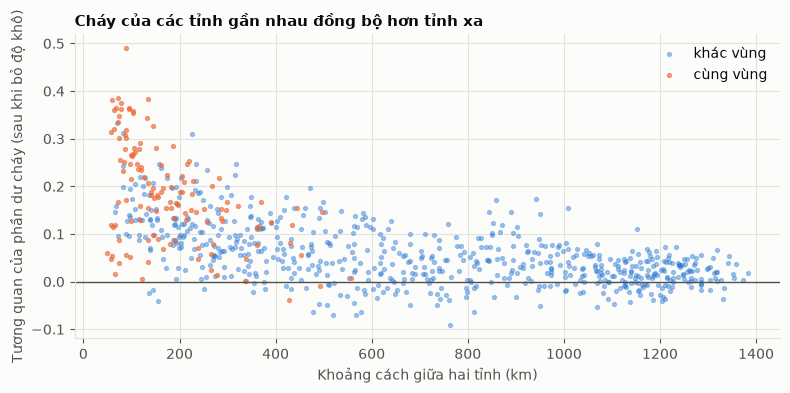

In [19]:
rho, p = spearmanr(pairs["km"], pairs["corr"])
early_pairs = pair_table(residuals[residuals.index.year <= SPLIT_SEASON])
late_pairs = pair_table(residuals[residuals.index.year > SPLIT_SEASON])
print("Toàn bộ: Spearman giữa khoảng cách và tương quan = %.2f (p = %.3g)" % (rho, p))
print("Nửa thăm dò: %.2f | nửa xác nhận: %.2f" % (spearmanr(early_pairs["km"], early_pairs["corr"])[0], spearmanr(late_pairs["km"], late_pairs["corr"])[0]))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pairs.loc[~pairs["cùng vùng"], "km"], pairs.loc[~pairs["cùng vùng"], "corr"], s=8, color=BLUE, alpha=0.4, label="khác vùng")
ax.scatter(pairs.loc[pairs["cùng vùng"], "km"], pairs.loc[pairs["cùng vùng"], "corr"], s=8, color=ORANGE, alpha=0.6, label="cùng vùng")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("Khoảng cách giữa hai tỉnh (km)")
ax.set_ylabel("Tương quan của phần dư cháy (sau khi bỏ độ khô)")
ax.set_title("Cháy của các tỉnh gần nhau đồng bộ hơn tỉnh xa")
ax.legend(frameon=False)
fig.tight_layout()

Phần dư cháy sau khi bỏ độ khô tương quan dương giữa các tỉnh và giảm theo khoảng cách: trung bình 0,18 đến 0,24 ở dưới 100 km, 0,09 đến 0,14 ở 200 đến 400 km, 0,03 đến 0,06 ở trên 400 km (Spearman giữa khoảng cách và tương quan −0,65, và −0,62, −0,61 ở hai nửa thời gian). Ở cùng khoảng cách, cặp tỉnh cùng vùng đồng bộ hơn cặp khác vùng. Mức đồng bộ còn khá ở 200 đến 400 km phù hợp với cả cháy lan lẫn các yếu tố chung như hoạt động của con người hoặc mây che làm vệ tinh bỏ sót; dữ liệu không tách được hai khả năng, và các giá trị p cho 780 cặp bị thổi phồng vì các cặp dùng chung tỉnh. Gộp bốn bằng chứng lại, cháy giống một quá trình có đà, có đợt và có tính vùng, điều mà một chỉ số chỉ dựa vào thời tiết ngày không nắm được.

Chương 5. Con người để lại dấu vết. Giả thuyết: Tết làm giảm cháy vì người dân ngừng đốt nương và đốt thực bì, nên hiệu ứng mạnh hơn ở tỉnh nhiều đất nông nghiệp và biến mất khi dịch Tết đi vài ngày. Thiết kế: so tỉ lệ cháy thực tế với mức kỳ vọng ở cùng vùng, tháng và mức độ khô (mức kỳ vọng tính từ các ngày cách Tết hơn 14 ngày), theo từng ngày trước và sau mùng 1 Tết.

In [20]:
tet_sample = ordered[ordered["analysis_sample"] == 1].copy()
tet_sample["season"] = tet_sample["season"].astype(int)
tet_sample["quintile"] = tet_sample.groupby(["region", "month"])["D13_hpa"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
tet_sample["stratum"] = tet_sample["region"].astype(str) + "|" + tet_sample["month"].astype(str) + "|" + tet_sample["quintile"].astype(str)

outside = tet_sample[tet_sample["days_from_tet"].abs() > 14]
expected = outside.groupby("stratum")["fire_any_forest"].mean().rename("expected")
tet_sample = tet_sample.join(expected, on="stratum")
tet_sample["resid"] = (tet_sample["fire_any_forest"] - tet_sample["expected"]) * 100

window = tet_sample[(tet_sample["days_from_tet"].abs() <= 14) & tet_sample["expected"].notna()].copy()
print("Ngày trong cửa sổ ±14 ngày quanh Tết:", len(window), "| tỉnh:", window["prov"].nunique(), "| năm Tết:", window["season"].nunique())

Ngày trong cửa sổ ±14 ngày quanh Tết: 12818 | tỉnh: 34 | năm Tết: 14


ngày,-14,-13,-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
chênh lệch,-3.9,2.8,0.2,-1.4,-3.3,2.3,7.1,9.0,5.0,7.0,6.2,-5.2,-5.4,-2.1,-4.4,-13.5,-7.2,-4.3,1.3,2.0,3.4,4.1,4.3,11.5,4.3,-0.4,-3.9,-5.5,1.9
ci_lo,-8.9,-3.0,-4.3,-5.9,-10.2,-3.1,2.4,3.1,0.5,0.9,2.9,-9.2,-10.9,-7.6,-9.9,-17.2,-13.7,-10.2,-5.6,-3.0,-1.7,-1.3,-2.3,5.4,-0.4,-6.5,-8.8,-10.1,-2.5
ci_hi,1.4,8.8,5.2,3.5,4.2,8.5,11.5,14.7,9.0,13.1,9.7,-1.4,-0.5,3.3,0.8,-9.4,-1.0,2.4,7.3,7.0,8.2,10.0,11.0,17.5,9.4,6.6,1.5,-1.3,5.4


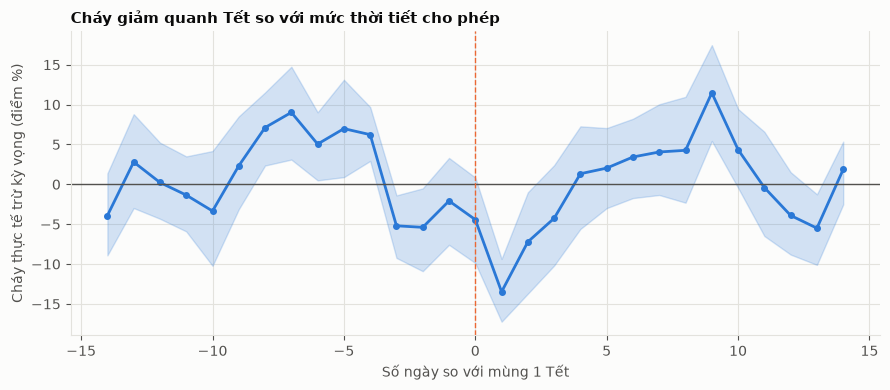

In [21]:
offsets = np.arange(-14, 15)
seasons = np.sort(window["season"].unique())
sums = np.zeros((len(seasons), len(offsets), 2))
for i, season in enumerate(seasons):
    part = window[window["season"] == season]
    for j, offset in enumerate(offsets):
        cell = part.loc[part["days_from_tet"] == offset, "resid"]
        sums[i, j] = [cell.sum(), len(cell)]

rng = np.random.default_rng(1)
curve = sums[:, :, 0].sum(axis=0) / sums[:, :, 1].sum(axis=0)
boots = []
for _ in range(2000):
    pick = rng.integers(0, len(seasons), len(seasons))
    boots.append(sums[pick, :, 0].sum(axis=0) / sums[pick, :, 1].sum(axis=0))
boots = np.array(boots)
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(offsets, lo, hi, color=BLUE, alpha=0.2)
ax.plot(offsets, curve, color=BLUE, marker="o", ms=4, lw=2)
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(0, color=ORANGE, lw=1, ls="--")
ax.set_xlabel("Số ngày so với mùng 1 Tết")
ax.set_ylabel("Cháy thực tế trừ kỳ vọng (điểm %)")
ax.set_title("Cháy giảm quanh Tết so với mức thời tiết cho phép")
fig.tight_layout()
pd.DataFrame({"ngày": offsets, "chênh lệch": curve.round(1), "ci_lo": lo.round(1), "ci_hi": hi.round(1)}).set_index("ngày").T

In [22]:
def window_effect(frame, radius=3):
    inside = frame[frame["days_from_tet"].abs() <= radius]
    return inside["resid"].mean()


def season_bootstrap(frame, statistic, n_boot=1000, seed=2):
    groups = {s: g for s, g in frame.groupby("season")}
    keys = list(groups)
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        pick = rng.choice(keys, len(keys))
        values.append(statistic(pd.concat([groups[k] for k in pick])))
    return np.percentile(values, [2.5, 97.5])


halves = {
    "toàn bộ": window,
    "nửa thăm dò (đến 2018)": window[window["season"] <= SPLIT_SEASON],
    "nửa xác nhận (từ 2019)": window[window["season"] > SPLIT_SEASON],
}
rows = []
for name, frame in halves.items():
    low, high = season_bootstrap(frame, window_effect, 500)
    rows.append({"phần": name, "số năm Tết": frame["season"].nunique(), "hiệu ứng ±3 ngày (điểm %)": window_effect(frame), "ci_lo": low, "ci_hi": high})
pd.DataFrame(rows).set_index("phần").round(2)

,số năm Tết,hiệu ứng ±3 ngày (điểm %),ci_lo,ci_hi
phần,,,,
toàn bộ,14,-6.01,-9.59,-2.42
nửa thăm dò (đến 2018),7,-3.23,-7.93,1.26
nửa xác nhận (từ 2019),7,-9.02,-13.88,-5.26


In [23]:
tet_dates = pd.DatetimeIndex(np.sort(tet_sample.loc[tet_sample["days_from_tet"] == 0, "date"].unique()))


def shifted_window_effect(shift):
    days = pd.DatetimeIndex(sorted({d + pd.Timedelta(days=int(shift + k)) for d in tet_dates for k in range(-3, 4)}))
    flag = tet_sample["date"].isin(days) & tet_sample["expected"].notna()
    return tet_sample.loc[flag, "resid"].mean()


placebo_shifts = [s for s in range(-60, 61) if abs(s) > 20]
placebo = np.array([shifted_window_effect(s) for s in placebo_shifts])
real = window_effect(window)
print("Hiệu ứng thực quanh Tết: %.2f điểm | ngày giả: trung bình %.2f, độ lệch chuẩn %.2f | số ngày giả cực đoan bằng hoặc hơn: %d / %d" % (
    real, placebo.mean(), placebo.std(), int((placebo <= real).sum()), len(placebo)))

Hiệu ứng thực quanh Tết: -6.01 điểm | ngày giả: trung bình 0.69, độ lệch chuẩn 1.37 | số ngày giả cực đoan bằng hoặc hơn: 0 / 80


In [24]:
province = tet_sample.groupby("prov").agg(crop=("crop_share", "first"), forest=("forest_share", "first"), built=("built_share", "first"), region=("region", "first"))
for column in ["crop", "forest", "built"]:
    province[f"{column}_group"] = pd.qcut(province[column], 3, labels=["thấp", "vừa", "cao"])
window = window.join(province[["crop_group", "forest_group", "built_group"]], on="prov")

rows = []
for column, title in [("crop_group", "tỉ lệ đất nông nghiệp"), ("forest_group", "tỉ lệ rừng"), ("built_group", "tỉ lệ đất xây dựng")]:
    for group in ["thấp", "vừa", "cao"]:
        frame = window[window[column] == group]
        low, high = season_bootstrap(frame, window_effect, 300)
        rows.append({"đặc trưng": title, "mức": group, "số tỉnh": frame["prov"].nunique(), "hiệu ứng ±3 ngày (điểm %)": window_effect(frame), "ci_lo": low, "ci_hi": high})
pd.DataFrame(rows).set_index(["đặc trưng", "mức"]).round(2)

số tỉnh  hiệu ứng ±3 ngày (điểm %)  ci_lo  ci_hi
đặc trưng             mức                                                   
tỉ lệ đất nông nghiệp thấp       14                      -4.42  -9.58   0.33
                      vừa         9                      -7.84 -12.26  -3.60
                      cao        11                      -6.53  -9.64  -3.02
tỉ lệ rừng            thấp       14                      -4.90  -7.91  -1.79
                      vừa         9                      -9.21 -13.22  -4.52
                      cao        11                      -4.80  -9.86  -0.27
tỉ lệ đất xây dựng    thấp       14                      -1.73  -7.09   2.56
                      vừa         9                      -3.59  -8.60   1.93
                      cao        11                     -13.43 -16.74  -9.91

Tết làm giảm điểm cháy rừng, nhưng cơ chế như giả thuyết ban đầu chưa được ủng hộ. Trong ±3 ngày quanh mùng 1, tỉ lệ cháy thấp hơn mức kỳ vọng khoảng 6,0 điểm phần trăm (khoảng tin cậy 95% từ −9,6 đến −2,4); không ngày giả nào trong 80 ngày giả đạt mức cực đoan như vậy. Đáy sâu nhất là mùng 2 (−13,5 điểm). Hai nửa thời gian cùng dấu nhưng khác độ lớn: nửa thăm dò −3,2 (khoảng tin cậy còn chứa 0), nửa xác nhận −9,0. Cháy cao hơn mức kỳ vọng 5 đến 9 điểm trong tuần trước Tết và hồi lên 4 đến 12 điểm sau Tết, tức cháy có thể bị dồn lại thay vì mất hẳn. Hiệu ứng không tăng theo tỉ lệ đất nông nghiệp (−4,4, −7,8, −6,5 từ thấp đến cao) nên giả thuyết đốt nương rẫy không được ủng hộ, mà mạnh nhất ở tỉnh nhiều đất xây dựng (−13,4 so với −1,7 và −3,6), gợi ý liên quan đến hoạt động gần khu dân cư. Phần phân nhóm này là thăm dò, chưa hiệu chỉnh đa so sánh. Tiếp theo xem hoạt động của con người còn lộ ra ở đâu: cháy trên đất nông nghiệp và đất cỏ ít phụ thuộc vào thời tiết hơn cháy trên rừng không?

In [25]:
hs = pd.read_csv(DATA / "interim" / "hotspots_enriched.csv", usecols=["prov", "ldate", "lc_center", "confidence"], parse_dates=["ldate"])
hs["conf"] = hs["confidence"].astype(str).str.lower()
hs = hs[hs["conf"].isin(["n", "h"])]
CLASS = {10: "rừng", 30: "đất cỏ", 40: "đất nông nghiệp"}
rows = []
for code_, name in CLASS.items():
    days = hs[hs["lc_center"] == code_].groupby(["prov", "ldate"]).size().rename("n").reset_index().rename(columns={"ldate": "date"})
    merged = sample.merge(days, on=["prov", "date"], how="left")
    merged["event"] = (merged["n"].fillna(0) > 0).astype(int)
    for region in FOREST:
        part = merged[merged["region"] == region]
        rows.append({
            "lớp phủ": name, "region": region, "tỉ lệ ngày có điểm cháy": part["event"].mean() * 100,
            "AUC độ hụt bão hòa": auc_within_month(part, "D13_hpa", "event"),
            "AUC P": auc_within_month(part, "P_primary", "event"),
        })
landcover = pd.DataFrame(rows)
print("AUC của độ hụt bão hòa theo lớp phủ tại điểm cháy")
display(landcover.pivot(index="region", columns="lớp phủ", values="AUC độ hụt bão hòa").reindex(FOREST)[list(CLASS.values())].round(3))
print("Tỉ lệ ngày có điểm cháy (%)")
landcover.pivot(index="region", columns="lớp phủ", values="tỉ lệ ngày có điểm cháy").reindex(FOREST)[list(CLASS.values())].round(1)

AUC của độ hụt bão hòa theo lớp phủ tại điểm cháy


lớp phủ,rừng,đất cỏ,đất nông nghiệp
region,,,
TB,0.846,0.836,0.801
DB,0.857,0.821,0.822
BTB,0.768,0.716,0.700
NTB,0.726,0.688,0.656
TN,0.782,0.772,0.706
DNB,0.643,0.616,0.622


Tỉ lệ ngày có điểm cháy (%)


lớp phủ,rừng,đất cỏ,đất nông nghiệp
region,,,
TB,47.8,42.6,20.1
DB,24.6,9.1,3.2
BTB,42.4,12.8,7.4
NTB,46.4,26.8,15.3
TN,70.5,65.7,42.7
DNB,36.2,17.1,19.3


In [26]:
rows = []
for name in CLASS.values():
    for half, mask in [("thăm dò", sample["season"] <= SPLIT_SEASON), ("xác nhận", sample["season"] > SPLIT_SEASON)]:
        code_ = [k for k, v in CLASS.items() if v == name][0]
        days = hs[hs["lc_center"] == code_].groupby(["prov", "ldate"]).size().rename("n").reset_index().rename(columns={"ldate": "date"})
        merged = sample[mask].merge(days, on=["prov", "date"], how="left")
        merged["event"] = (merged["n"].fillna(0) > 0).astype(int)
        values = {r: auc_within_month(merged[merged["region"] == r], "D13_hpa", "event") for r in FOREST}
        rows.append({"lớp phủ": name, "nửa": half, **values})
pd.DataFrame(rows).set_index(["lớp phủ", "nửa"]).round(3)

TB     DB    BTB    NTB     TN    DNB
lớp phủ         nửa                                               
rừng            thăm dò   0.859  0.851  0.808  0.743  0.782  0.634
                xác nhận  0.834  0.859  0.729  0.718  0.776  0.640
đất cỏ          thăm dò   0.850  0.829  0.754  0.696  0.764  0.605
                xác nhận  0.823  0.808  0.672  0.677  0.772  0.626
đất nông nghiệp thăm dò   0.823  0.821  0.727  0.659  0.691  0.616
                xác nhận  0.778  0.812  0.674  0.648  0.719  0.630

Giả thuyết được ủng hộ ở mức vừa phải. Độ hụt bão hòa tách ngày có cháy rừng tốt hơn ngày có cháy đất nông nghiệp ở cả sáu vùng, chênh từ 0,02 đến 0,08 AUC (Bắc Trung Bộ 0,77 so với 0,70, Nam Trung Bộ 0,73 so với 0,66, Tây Nguyên 0,78 so với 0,71), và đất cỏ nằm giữa hai nhóm. Thứ tự này giữ nguyên ở cả hai nửa thời gian. Cháy nông nghiệp cũng hiếm hơn nhiều (ví dụ Đông Bắc 3% ngày so với 25% với rừng). Tức phần cháy do con người quyết định, như đốt đồng, ít chịu chi phối của thời tiết, và là một lý do nữa khiến chỉ số thời tiết như P bỏ sót nhiều.

Chương 6. Dữ liệu cũng có câu chuyện riêng: điểm cháy giảm mạnh sau 2015 nhưng chưa rõ do cháy thật hay do dữ liệu. Giả thuyết: nếu sụt giảm do thiết bị hoặc xử lý dữ liệu thì phải giảm đồng thời ở mọi vùng, phân phối các đại lượng cảm biến (kích thước điểm ảnh, nhiệt độ sáng, công suất cháy) phải đổi theo, và vẫn còn sau khi bỏ ảnh hưởng của độ khô. Mốc 2015 được chọn sau khi nhìn dữ liệu Tây Nguyên nên kết quả mang tính thăm dò.

In [27]:
hs = pd.read_csv(
    DATA / "interim" / "hotspots_enriched.csv",
    usecols=["prov", "ldate", "confidence", "scan", "track", "bright_ti4", "frp", "daynight", "lc_center"],
    parse_dates=["ldate"],
)
hs["year"] = hs["ldate"].dt.year
hs = hs[hs["year"] <= 2025]
hs["conf"] = hs["confidence"].astype(str).str.lower()
sensor = hs.groupby("year").agg(
    điểm=("frp", "size"),
    scan_trung_vị=("scan", "median"),
    track_trung_vị=("track", "median"),
    nhiệt_độ_sáng_trung_vị=("bright_ti4", "median"),
    frp_trung_vị=("frp", "median"),
    frp_p90=("frp", lambda s: s.quantile(0.9)),
    tỉ_lệ_low=("conf", lambda s: (s == "l").mean() * 100),
    tỉ_lệ_ban_đêm=("daynight", lambda s: (s == "N").mean() * 100),
)
sensor.round(2).T

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
điểm,80272.00,80934.00,101822.00,99968.00,89900.00,46039.00,56915.00,71211.00,69559.00,54925.00,37343.00,57192.00,58601.00,42586.00
scan_trung_vị,0.44,0.44,0.43,0.44,0.44,0.43,0.44,0.44,0.43,0.43,0.43,0.44,0.44,0.43
track_trung_vị,0.43,0.44,0.43,0.44,0.45,0.43,0.43,0.44,0.43,0.44,0.44,0.44,0.45,0.44
nhiệt_độ_sáng_trung_vị,335.98,336.27,336.27,336.53,336.31,336.03,335.63,335.69,335.80,335.75,334.95,335.51,335.90,335.11
frp_trung_vị,5.06,5.05,5.04,5.12,5.02,4.94,4.77,4.74,4.74,4.75,4.68,4.71,4.73,4.57
frp_p90,17.32,16.63,17.05,16.46,16.75,15.07,14.10,14.23,14.36,13.62,13.42,13.86,13.10,12.50
tỉ_lệ_low,7.39,7.47,9.37,9.79,8.29,8.16,7.86,8.58,8.48,7.86,5.01,7.46,8.35,5.67
tỉ_lệ_ban_đêm,13.32,11.56,12.40,11.29,15.58,9.58,12.77,15.05,15.54,12.14,10.10,13.49,13.63,12.10


In [28]:
good = hs[hs["conf"].isin(["n", "h"])].copy()
good["region"] = good["prov"].map(region_of)
good = good[good["region"].isin(FOREST)]
good["season"] = [season_label(t, SEASON[r]) for t, r in zip(good["ldate"], good["region"])]
good = good.dropna(subset=["season"])
good["season"] = good["season"].astype(int)

counts = good.groupby(["region", "season"]).size().unstack(0)
rows = []
for region in FOREST:
    c = counts.loc[COMPLETE[region], region]
    early, late = c[c.index <= 2015], c[c.index >= 2016]
    rows.append({"vùng": VN[region], "trung bình đến 2015": early.mean(), "trung bình từ 2016": late.mean(), "tỉ số": late.mean() / early.mean(), "mùa lớn nhất": int(c.idxmax()), "mùa nhỏ nhất": int(c.idxmin())})
print("Số điểm cháy (độ tin cậy nominal và high) theo mùa, trước và sau 2015")
pd.DataFrame(rows).set_index("vùng").round(2)

Số điểm cháy (độ tin cậy nominal và high) theo mùa, trước và sau 2015


,trung bình đến 2015,trung bình từ 2016,tỉ số,mùa lớn nhất,mùa nhỏ nhất
vùng,,,,,
Tây Bắc,16307.00,8806.22,0.54,2013,2021
Đông Bắc,3339.25,3216.78,0.96,2024,2017
Bắc Trung Bộ,4048.00,2832.20,0.70,2016,2025
Nam Trung Bộ,10473.33,6741.60,0.64,2014,2017
Tây Nguyên,28137.50,12769.56,0.45,2014,2021
Đông Nam Bộ,2416.50,1634.67,0.68,2015,2016


Tỉ lệ ngày cháy so với kỳ vọng theo vùng, tháng và độ khô, trước và sau 2015 (điểm phần trăm)


,trung bình đến 2015,trung bình từ 2016,chênh lệch,ci_lo,ci_hi
vùng,,,,,
Tây Bắc,3.05,-1.13,-4.18,-9.48,0.41
Đông Bắc,-0.11,0.13,0.24,-3.12,3.55
Bắc Trung Bộ,2.08,-0.83,-2.91,-5.90,0.24
Nam Trung Bộ,6.78,-2.03,-8.81,-11.61,-5.68
Tây Nguyên,9.04,-3.93,-12.97,-17.51,-8.62
Đông Nam Bộ,3.10,-1.36,-4.46,-8.61,0.31


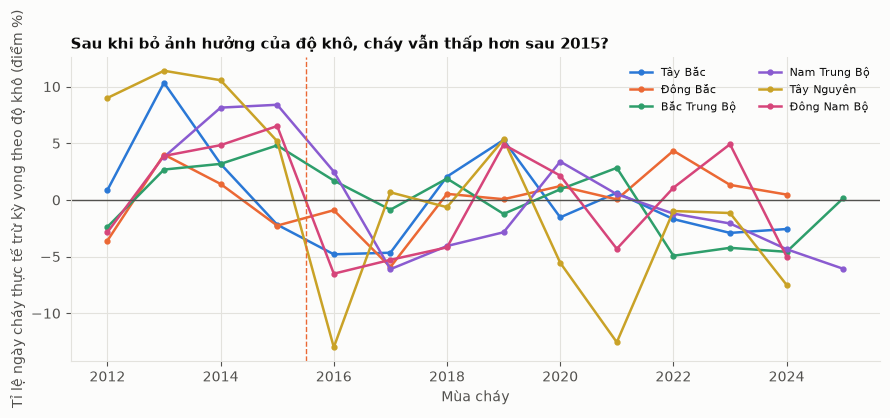

In [29]:
sample["quintile"] = sample.groupby(["region", "month"])["D13_hpa"].transform(lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
sample["stratum"] = sample["region"].astype(str) + "|" + sample["month"].astype(str) + "|" + sample["quintile"].astype(str)
sample["expected"] = sample.groupby("stratum")["fire_any_forest"].transform("mean")
sample["resid"] = (sample["fire_any_forest"] - sample["expected"]) * 100

yearly = sample.groupby(["region", "season"])["resid"].mean().unstack(0)
rng = np.random.default_rng(0)
rows = []
for region in FOREST:
    r = yearly.loc[COMPLETE[region], region]
    early, late = r[r.index <= 2015].values, r[r.index >= 2016].values
    boots = [rng.choice(late, len(late)).mean() - rng.choice(early, len(early)).mean() for _ in range(2000)]
    rows.append({"vùng": VN[region], "trung bình đến 2015": early.mean(), "trung bình từ 2016": late.mean(), "chênh lệch": late.mean() - early.mean(), "ci_lo": np.percentile(boots, 2.5), "ci_hi": np.percentile(boots, 97.5)})
adjusted = pd.DataFrame(rows).set_index("vùng")

fig, ax = plt.subplots(figsize=(9, 4))
for color, region in zip(PALETTE, FOREST):
    r = yearly.loc[COMPLETE[region], region]
    ax.plot(r.index, r.values, marker="o", ms=3.5, lw=1.8, color=color, label=VN[region])
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(2015.5, color=ORANGE, ls="--", lw=1)
ax.set_xlabel("Mùa cháy")
ax.set_ylabel("Tỉ lệ ngày cháy thực tế trừ kỳ vọng theo độ khô (điểm %)")
ax.set_title("Sau khi bỏ ảnh hưởng của độ khô, cháy vẫn thấp hơn sau 2015?")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
print("Tỉ lệ ngày cháy so với kỳ vọng theo vùng, tháng và độ khô, trước và sau 2015 (điểm phần trăm)")
adjusted.round(2)

In [30]:
sync = yearly.copy()
sync = sync[sync.index.isin(range(2013, 2025))]
corr = sync.corr().loc[FOREST, FOREST]
corr.index = [VN[r] for r in corr.index]
corr.columns = [VN[r] for r in corr.columns]
print("Tương quan giữa các vùng của phần dư tỉ lệ cháy theo mùa (các mùa 2013-2024)")
corr.round(2)

Tương quan giữa các vùng của phần dư tỉ lệ cháy theo mùa (các mùa 2013-2024)


,Tây Bắc,Đông Bắc,Bắc Trung Bộ,Nam Trung Bộ,Tây Nguyên,Đông Nam Bộ
Tây Bắc,1.00,0.52,0.33,0.23,0.64,0.43
Đông Bắc,0.52,1.00,-0.20,0.22,0.18,0.36
Bắc Trung Bộ,0.33,-0.20,1.00,0.69,0.22,0.13
Nam Trung Bộ,0.23,0.22,0.69,1.00,0.33,0.55
Tây Nguyên,0.64,0.18,0.22,0.33,1.00,0.72
Đông Nam Bộ,0.43,0.36,0.13,0.55,0.72,1.00


Giả thuyết do thiết bị không được ủng hộ đầy đủ nhưng cũng chưa loại trừ hẳn. Chống lại: sụt giảm không đồng đều (Đông Bắc gần như không giảm, tỉ số 0,96; Tây Nguyên 0,45; Tây Bắc 0,54; Nam Trung Bộ 0,64); kích thước điểm ảnh và nhiệt độ sáng trung vị gần như không đổi suốt 14 năm; và sau khi bỏ ảnh hưởng của độ khô, chỉ Tây Nguyên (−13,0 điểm phần trăm, khoảng tin cậy từ −17,5 đến −8,6) và Nam Trung Bộ (−8,8; từ −11,6 đến −5,7) vẫn thấp rõ rệt. Ủng hộ khả năng có yếu tố chung: công suất cháy trung vị và phân vị 90 giảm dần từ 2017 (phân vị 90 từ 17,3 xuống 12,5 MW), và phần dư theo mùa tương quan dương giữa nhiều cặp vùng liền kề. Nhìn riêng Tây Nguyên theo loại đất:

In [31]:
hot = pd.read_csv(DATA / "interim" / "hotspots_enriched.csv", usecols=["prov", "ldate", "lc_center", "confidence", "daynight", "frp"], parse_dates=["ldate"])
region_of = df.groupby("prov")["region"].first()
hot["region"] = hot["prov"].map(region_of)
hot = hot[hot["region"].isin(FOREST)].copy()
hot["season"] = [season_label(t, SEASON[r]) for t, r in zip(hot["ldate"], hot["region"])]
hot = hot.dropna(subset=["season"])
hot["season"] = hot["season"].astype(int)
hot["conf"] = hot["confidence"].astype(str).str.lower()
hot = hot[hot["conf"].isin(["n", "h"])]
LAND = {10: "rừng (cây)", 20: "cây bụi", 30: "đất cỏ", 40: "đất nông nghiệp", 50: "đất xây dựng"}
hot["land"] = hot["lc_center"].map(LAND).fillna("khác")
season_days = df[df["in_season"] == 1].assign(season=lambda x: x["season"].astype(int)).groupby(["region", "season"]).size()
n_prov = df.groupby("region")["prov"].nunique()
per_prov = season_days.div(n_prov, level="region")
COMPLETE = {r: sorted(per_prov[r][per_prov[r] >= 0.95 * per_prov[r].max()].index) for r in FOREST}
tn = hot[(hot["region"] == "TN") & hot["season"].isin(COMPLETE["TN"])]
counts = tn.groupby(["season", "land"]).size().unstack(fill_value=0)
counts["tổng"] = counts.sum(axis=1)
print("Số điểm cháy ở Tây Nguyên theo mùa và lớp phủ tại điểm cháy (các mùa đủ trong dữ liệu)")
counts

Số điểm cháy ở Tây Nguyên theo mùa và lớp phủ tại điểm cháy (các mùa đủ trong dữ liệu)


land,cây bụi,khác,rừng (cây),đất cỏ,đất nông nghiệp,đất xây dựng,tổng
season,,,,,,,
2012,4,153,14218,10738,2820,85,28018
2013,3,152,13969,11321,2696,118,28259
2014,4,124,14352,11137,2719,92,28428
2015,3,138,14384,10612,2596,112,27845
2016,2,76,5343,4733,1401,62,11617
2017,1,67,7984,7001,1806,61,16920
2018,1,64,7927,6334,1664,53,16043
2019,3,69,10660,7508,1750,27,20017
2020,2,43,5974,5070,1379,12,12480


,trung bình nửa đầu,trung bình nửa sau,rho theo mùa,p,tỉ số nửa sau / nửa đầu
lớp phủ,,,,,
cây bụi,2.571,1.833,-0.663,0.013,0.713
khác,110.571,35.000,-0.955,0.000,0.317
rừng (cây),11168.143,6063.000,-0.753,0.003,0.543
đất cỏ,8839.429,4362.833,-0.874,0.000,0.494
đất nông nghiệp,2243.143,1240.167,-0.863,0.000,0.553
đất xây dựng,83.286,21.500,-0.830,0.000,0.258
tổng,22447.143,11724.333,-0.830,0.000,0.522


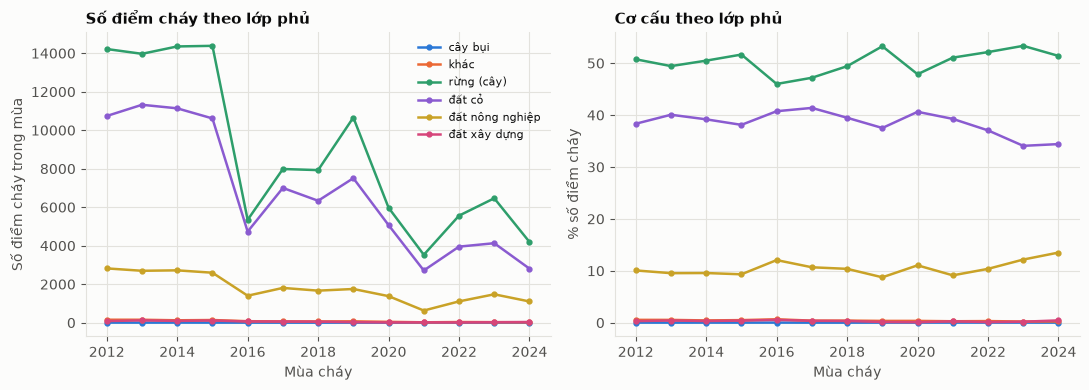

In [32]:
shares = counts.drop(columns="tổng").div(counts["tổng"], axis=0) * 100
rows = []
for column in list(counts.columns):
    rho, p = spearmanr(counts.index, counts[column])
    rows.append({"lớp phủ": column, "trung bình nửa đầu": counts.loc[counts.index <= SPLIT_SEASON, column].mean(), "trung bình nửa sau": counts.loc[counts.index > SPLIT_SEASON, column].mean(), "rho theo mùa": rho, "p": p})
trend = pd.DataFrame(rows).set_index("lớp phủ")
trend["tỉ số nửa sau / nửa đầu"] = trend["trung bình nửa sau"] / trend["trung bình nửa đầu"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for color, column in zip(PALETTE, [c for c in counts.columns if c != "tổng"]):
    axes[0].plot(counts.index, counts[column], marker="o", ms=3.5, lw=1.8, color=color, label=column)
    axes[1].plot(shares.index, shares[column], marker="o", ms=3.5, lw=1.8, color=color)
axes[0].set_title("Số điểm cháy theo lớp phủ")
axes[0].set_ylabel("Số điểm cháy trong mùa")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_title("Cơ cấu theo lớp phủ")
axes[1].set_ylabel("% số điểm cháy")
for ax in axes:
    ax.set_xlabel("Mùa cháy")
fig.tight_layout()
trend.round(3)

Số điểm cháy ở Tây Nguyên giảm xấp xỉ một nửa ở mọi lớp phủ (nửa sau so với nửa đầu: rừng 0,54, đất cỏ 0,49, đất nông nghiệp 0,55) và cơ cấu theo lớp phủ gần như không đổi, nên mức giảm không tập trung ở đất nông nghiệp như dự đoán ban đầu. Chuỗi trông như một bước nhảy (bốn mùa 2012 đến 2015 đều khoảng 28 nghìn điểm rồi tụt còn 11 đến 20 nghìn từ mùa 2016) hơn là giảm dần, và số điểm cháy giảm ở năm trong sáu vùng. Dữ liệu hiện có chưa đủ để phân biệt thay đổi thật của cháy, chính sách hay sử dụng đất với thay đổi về thiết bị hay xử lý dữ liệu; đây là việc cần kiểm tra bằng nguồn dữ liệu độc lập.

Chương 7. Kiểm tra độ vững. Kết luận về P có phụ thuộc vào cách định nghĩa cháy rừng (ngưỡng tỉ lệ cây 0,5, độ tin cậy nominal và high) hay không.

In [33]:
hot = pd.read_csv(DATA / "interim" / "hotspots_enriched.csv", usecols=["prov", "ldate", "confidence", "tree_frac"], parse_dates=["ldate"])
hot["conf"] = hot["confidence"].astype(str).str.lower()
definitions = {
    "cây ≥ 0,5, nominal+high (chuẩn)": (hot["tree_frac"] >= 0.5) & hot["conf"].isin(["n", "h"]),
    "cây ≥ 0,3": (hot["tree_frac"] >= 0.3) & hot["conf"].isin(["n", "h"]),
    "cây ≥ 0,7": (hot["tree_frac"] >= 0.7) & hot["conf"].isin(["n", "h"]),
    "cây ≥ 0,9": (hot["tree_frac"] >= 0.9) & hot["conf"].isin(["n", "h"]),
    "chỉ độ tin cậy high": (hot["tree_frac"] >= 0.5) & (hot["conf"] == "h"),
}

rows = []
for name, mask in definitions.items():
    counts = hot[mask].groupby(["prov", "ldate"]).size().rename("n").reset_index().rename(columns={"ldate": "date"})
    alt = sample.merge(counts, on=["prov", "date"], how="left")
    alt["y_alt"] = (alt["n"].fillna(0) > 0).astype(int)
    for region in FOREST:
        part = alt[alt["region"] == region]
        rows.append({
            "định nghĩa": name, "region": region, "rate": part["y_alt"].mean() * 100,
            "AUC của P": auc_within_month(part, "P_primary", "y_alt"), "AUC của độ hụt bão hòa": auc_within_month(part, "D13_hpa", "y_alt"),
        })
robust = pd.DataFrame(rows)
print("Tỉ lệ ngày cháy (%) theo định nghĩa")
display(robust.pivot(index="định nghĩa", columns="region", values="rate")[FOREST].round(1))
print("AUC của chỉ số P trong cùng tỉnh-tháng theo định nghĩa")
display(robust.pivot(index="định nghĩa", columns="region", values="AUC của P")[FOREST].round(3))
print("AUC của độ hụt bão hòa 13h theo định nghĩa")
robust.pivot(index="định nghĩa", columns="region", values="AUC của độ hụt bão hòa")[FOREST].round(3)

Tỉ lệ ngày cháy (%) theo định nghĩa


region,TB,DB,BTB,NTB,TN,DNB
định nghĩa,,,,,,
chỉ độ tin cậy high,10.1,3.1,5.2,5.2,15.0,1.4
"cây ≥ 0,3",50.9,26.1,45.8,48.8,73.9,41.4
"cây ≥ 0,5, nominal+high (chuẩn)",47.5,25.2,42.5,46.6,70.2,35.6
"cây ≥ 0,7",41.6,23.5,39.9,43.2,64.5,27.7
"cây ≥ 0,9",28.3,19.1,33.7,34.4,50.7,16.1


AUC của chỉ số P trong cùng tỉnh-tháng theo định nghĩa


region,TB,DB,BTB,NTB,TN,DNB
định nghĩa,,,,,,
chỉ độ tin cậy high,0.650,0.717,0.687,0.668,0.656,0.650
"cây ≥ 0,3",0.721,0.706,0.695,0.674,0.736,0.623
"cây ≥ 0,5, nominal+high (chuẩn)",0.715,0.708,0.695,0.672,0.723,0.617
"cây ≥ 0,7",0.703,0.709,0.694,0.667,0.712,0.604
"cây ≥ 0,9",0.686,0.717,0.686,0.654,0.702,0.586


AUC của độ hụt bão hòa 13h theo định nghĩa


region,TB,DB,BTB,NTB,TN,DNB
định nghĩa,,,,,,
chỉ độ tin cậy high,0.762,0.852,0.742,0.698,0.690,0.635
"cây ≥ 0,3",0.854,0.854,0.772,0.734,0.800,0.643
"cây ≥ 0,5, nominal+high (chuẩn)",0.846,0.857,0.771,0.730,0.780,0.633
"cây ≥ 0,7",0.830,0.857,0.767,0.721,0.763,0.622
"cây ≥ 0,9",0.813,0.860,0.760,0.702,0.722,0.619


Khi đổi ngưỡng tỉ lệ cây từ 0,3 đến 0,9 hoặc chỉ giữ điểm có độ tin cậy cao, tỉ lệ ngày cháy thay đổi rất nhiều (Đông Nam Bộ từ 36% xuống 16% khi đòi cây từ 0,9) nhưng AUC của cả P và độ hụt bão hòa ít đổi, và độ hụt bão hòa vẫn tách ngày cháy tốt hơn P ở mọi định nghĩa và mọi vùng, trừ Đông Nam Bộ khi chỉ giữ điểm độ tin cậy cao. Kết luận chương 1 vì vậy không phụ thuộc vào ngưỡng 0,5.

Tóm lại. Chỉ số P có ích hơn khí hậu nhưng không đủ để làm công cụ cảnh báo chung cho cả nước, vì ba lý do. Một, nó thua một biến đo ngay trong ngày ở mọi vùng, vì khô kéo dài quá một tuần không làm cháy dễ hơn và mưa nhỏ dưới 5 mm đã đủ dập cháy ở phần lớn các vùng. Hai, ngưỡng độ khô để cháy bắt đầu khác nhau gần gấp đôi giữa các vùng và đổi theo vĩ độ và độ cao, nên một thang chung không có nghĩa như nhau ở mọi nơi. Ba, cháy là một quá trình có đà, có đợt, có tính vùng và chịu tác động của con người (Tết, đốt đồng), phần mà một chỉ số chỉ dựa vào thời tiết bỏ sót. Về hàm ý, cảnh báo cháy nên dựa vào các biến trong ngày như độ hụt bão hòa, được hiệu chỉnh riêng cho từng vùng, và nên theo dõi trạng thái đợt cháy đang diễn ra. Hạn chế: kết quả chỉ là mối liên hệ chứ chưa phải nhân quả; biến kết quả là điểm cháy vệ tinh nên chịu ảnh hưởng của mây che; mốc 2015 và các phân nhóm theo thuộc tính tỉnh là thăm dò, chưa hiệu chỉnh đa so sánh; và việc sụt giảm điểm cháy sau 2015 chưa rõ nguyên nhân.